# Receptor–Cytokine Models and Parameter Fitting

In this notebook, we use simple mathematical functions to describe how cells can respond to signaling molecules.

We will first work with the **Hill function**, then compare it with a more mechanistic **Monod–Wyman–Changeux (MWC) model**, and finally use **parameter fitting** to approximate the MWC response with a Hill function.

> ## Programming includes looking things up
> **You are encouraged to use the internet while working through this notebook.** Looking up syntax, examples, documentation, and error messages is a normal part of programming.
>
> **The teachers are also available for questions at any time.**

The main workflow is:

**biological mechanism → mathematical response function → simulation → parameter fitting → interpretation**


## 1. Import the packages

We use:

- **NumPy** for calculations,
- **Matplotlib** for plotting,
- **SciPy** for parameter fitting.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


### If a package is missing

In Jupyter, you can install the required packages with:

```python
%pip install numpy matplotlib scipy
```

Then run the import cell again.


## 2. From receptor binding to cell activation

Cells can communicate using signaling molecules such as cytokines. A simplified picture is:

**signaling molecule → receptor binding → intracellular response → cell activation**

A Hill function is often used to describe a saturating response:

$f(x;n,K)=\frac{x^n}{K^n+x^n}$

where:

- $x$ is the signaling-molecule concentration,
- $K$ controls where the response reaches half of its maximum,
- $n$ controls how steep or switch-like the response is.

The output lies between approximately 0 and 1 and can be interpreted as an activation fraction.


### Exercise 1: implement the Hill function

Complete the Python function for

$f(x;n,K)=\frac{x^n}{K^n+x^n}$


In [2]:
def hill_function(x, n, K):
    return x**n / (K**n + x**n)


## 3. Explore the Hill coefficient $n$

The parameter $n$ changes the steepness of the response.

We keep $K=3$ fixed and compare several values of $n$.


### Exercise 2: vary $n$

Use:

```python
n_values = [0.5, 1, 2, 3, 4, 6]
K_fixed = 3
```

Plot one Hill curve for each value of $n$.


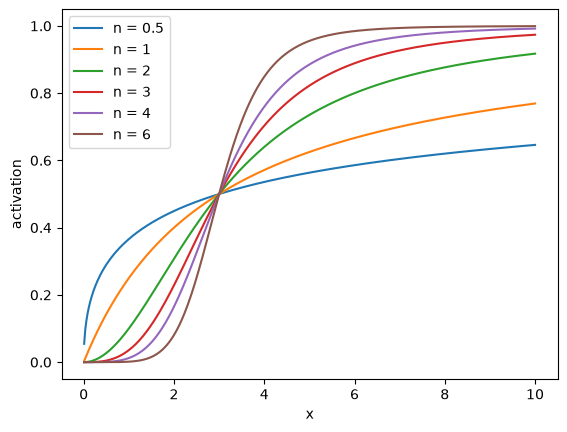

In [3]:
x = np.linspace(0.01, 10, 400)

n_values = [0.5, 1, 2, 3, 4, 6]
K_fixed = 3

for n in n_values:
    y = hill_function(x, n=n, K=K_fixed)
    plt.plot(x, y, label=f"n = {n}")

plt.xlabel("x")
plt.ylabel("activation")
plt.legend()
plt.show()


### What should you notice?

For larger $n$, the curve becomes steeper. The response becomes more switch-like.

The Hill coefficient therefore changes the **shape** of the response.


## 4. Explore the parameter $K$

Now keep $n=3$ fixed and vary $K$.

For the Hill function, the response is $0.5$ when $x=K$.


### Exercise 3: vary $K$

Use:

```python
K_values = [1, 2, 3, 4, 5, 7]
n_fixed = 3
```

Plot all curves together.


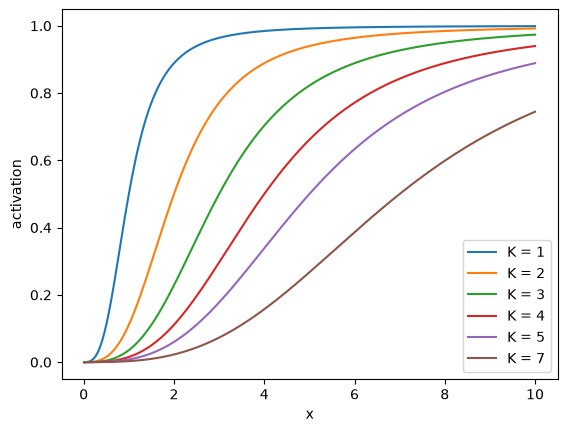

In [4]:
K_values = [1, 2, 3, 4, 5, 7]
n_fixed = 3

for K in K_values:
    y = hill_function(x, n=n_fixed, K=K)
    plt.plot(x, y, label=f"K = {K}")

plt.xlabel("x")
plt.ylabel("activation")
plt.legend()
plt.show()


### What should you notice?

Changing $K$ mainly shifts the activation curve along the x-axis.

A larger $K$ means that a larger signaling-molecule concentration is needed to reach the same activation level.


## 5. A more mechanistic model: the MWC model

The Hill function is a compact phenomenological description. A more detailed model can explicitly represent different receptor conformations and ligand binding. One example is the **Monod–Wyman–Changeux (MWC) model**.

For this exercise, the activation function is

$F(x;K_1,K_2,K_3,n)=
\frac{(1+x/K_2)^n}
{K_3(1+x/K_1)^n+(1+x/K_2)^n}$

We use the parameter values:

- $K_1=10$
- $K_2=0.1$
- $K_3=100$
- $n=5$


### Exercise 4: implement the MWC activation function

Translate the equation above into Python.


In [5]:
def F_MWC(x, K1, K2, K3, n):
    return (1 + x / K2)**n / (
        K3 * (1 + x / K1)**n + (1 + x / K2)**n
    )


### Exercise 5: simulate the MWC response

Simulate the MWC function for:

```python
K1 = 10
K2 = 0.1
K3 = 100
n = 5
```

Use $x$ values from 0 to 2 and plot the activation curve.


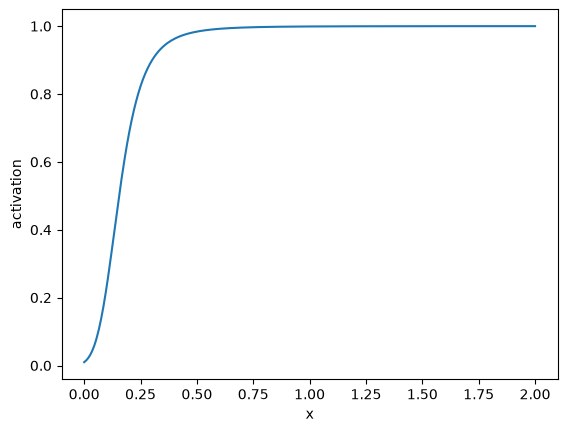

In [6]:
K1 = 10
K2 = 0.1
K3 = 100
n_MWC = 5

x_mwc = np.linspace(0, 2, 400)

y_mwc = F_MWC(x_mwc, K1, K2, K3, n_MWC)

plt.plot(x_mwc, y_mwc)
plt.xlabel("x")
plt.ylabel("activation")
plt.show()


## 6. What does parameter fitting mean?

We now ask a different question:

> Can the simpler Hill function reproduce the activation curve generated by the more detailed MWC model?

We know the $x$ values and the corresponding MWC activation values.

We then let Python search for values of $n$ and $K$ in the Hill function that make the Hill curve as close as possible to the MWC curve.

We use:

```python
curve_fit(model_function, x_values, y_values, p0=initial_guess)
```

`p0` provides starting guesses for the parameters.


### Exercise 6: fit the Hill function to the MWC model

Use:

```python
p0 = [2.0, 1.0]
```

Then:

1. call `curve_fit`,
2. extract the fitted `n` and `K`,
3. print both fitted parameters.


In [7]:
p0 = [2.0, 1.0]

params, covariance = curve_fit(
    hill_function,
    x_mwc,
    y_mwc,
    p0=p0,
    maxfev=5000
)

n_fit, K_fit = params

print(f"Fitted n = {n_fit:.2f}")
print(f"Fitted K = {K_fit:.2f}")


Fitted n = 3.06
Fitted K = 0.15


/tmp/ipykernel_54523/3531737570.py:2: RuntimeWarning: divide by zero encountered in power
  return x**n / (K**n + x**n)
/tmp/ipykernel_54523/3531737570.py:2: RuntimeWarning: invalid value encountered in scalar power
  return x**n / (K**n + x**n)


### Exercise 7: compare both models visually

Plot:

- the MWC activation curve,
- the fitted Hill function.

Add a legend that includes the fitted values of $n$ and $K$.


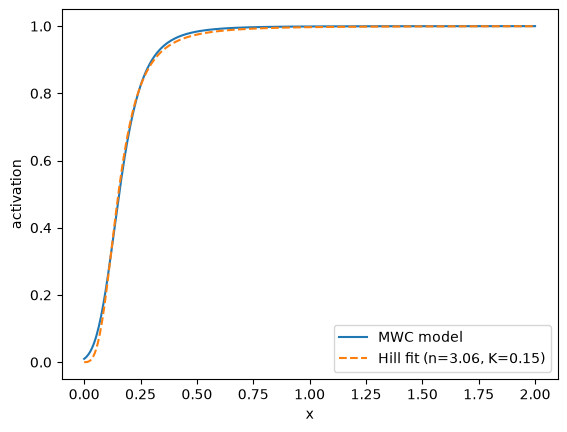

In [8]:
hill_fit = hill_function(x_mwc, n_fit, K_fit)

plt.plot(x_mwc, y_mwc, label="MWC model")
plt.plot(
    x_mwc,
    hill_fit,
    "--",
    label=f"Hill fit (n={n_fit:.2f}, K={K_fit:.2f})"
)

plt.xlabel("x")
plt.ylabel("activation")
plt.legend()
plt.show()


## 7. Interpretation

The fitted Hill function can approximate the shape of the more detailed MWC response very closely.

However, the parameters do **not** have to correspond directly between the two models.

For example, the MWC model uses $n=5$, while the fitted Hill coefficient can be around $n\approx3$.

This illustrates an important modeling principle:

> **A simpler model can reproduce the observed behavior of a more complex model without reproducing its underlying mechanism.**

Therefore, a good fit does not automatically mean that every fitted parameter has the same mechanistic interpretation as a parameter in the original system.


## Summary: what you learned

In this notebook, you learned how to:

- implement a Hill function in Python,
- interpret the roles of $n$ and $K$,
- explore parameter effects by simulation,
- implement a more detailed MWC activation model,
- understand the basic idea of parameter fitting,
- use `curve_fit`,
- compare a fitted model with a target curve,
- distinguish between **reproducing behavior** and **reproducing mechanism**.

The main workflow is:

**choose a model → simulate → compare with data or another model → fit parameters → visualize → interpret**
